# 01. Data exploration

Exploratory analysis of the 600 generated images and the 54 real drone tiles. It follows the eight objectives of the course guide: sanity, coverage, realism, variability, label quality, leakage, balance and difficulty. All numbers come from `04_cv_experiment/src/eda.py`, which writes `results/eda/eda.json`. Each section ends with what we decided.

In [1]:
import csv, json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

ROOT = Path("..").resolve()
PALETTE = np.array([(240,234,222),(214,178,112),(92,64,51),(196,78,56),(58,90,120)], np.uint8)
CLASSES = ["background", "floor", "wall", "installation", "pit"]
load = lambda p: json.loads((ROOT / p).read_text(encoding="utf-8"))

E, raw = load("results/eda/eda.json"), load("results/eda/eda_raw.json")
print(E["n_images"], "images from", E["n_layouts"], "layouts")

600 images from 300 layouts


## 1. Samples

Each image was generated from a random layout. The layout mask is the label.

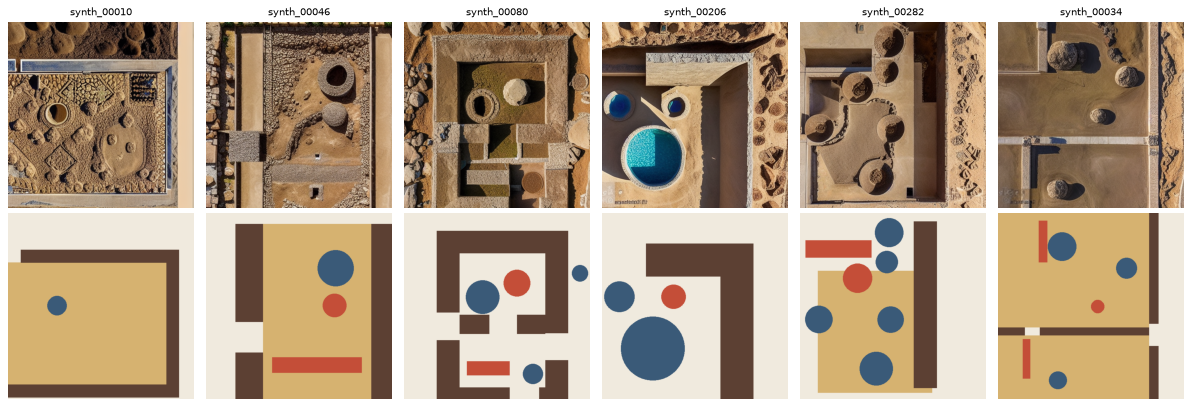

In [2]:
SYN = ROOT / "04_cv_experiment/data/synthetic"
names = ["synth_00010", "synth_00046", "synth_00080", "synth_00206", "synth_00282", "synth_00034"]
fig, ax = plt.subplots(2, 6, figsize=(15, 5.2))
for j, n in enumerate(names):
    ax[0, j].imshow(Image.open(SYN / f"images/{n}_s0.png")); ax[0, j].set_title(n, fontsize=9)
    ax[1, j].imshow(PALETTE[np.array(Image.open(SYN / f"labels/{n}.png"))])
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

## 2. Sanity

In [3]:
print(json.dumps(E["sanity"], indent=1))

{
 "image_sizes": {
  "(512, 512)": 600
 },
 "missing_values": {
  "built_iou": 2
 },
 "exact_duplicate_images": 0,
 "blank_images": [],
 "labels_with_invalid_values": 0
}


**Decision.** Two images have no `built_iou` because their layouts contain nothing built. Two black images from the safety filter were found and regenerated earlier (issue 5), so none are left.

## 3. Coverage and balance

layouts that contain each class: {'background': 296, 'floor': 254, 'wall': 244, 'installation': 209, 'pit': 246}
compositions: {'pit_in_floor': 147, 'pit_in_open': 180, 'installation_on_floor': 151, 'installation_in_open': 76, 'wall_south_of_pit': 47, 'wall_north_of_pit': 38}
periods: {'Chalcolithic': 54, 'Roman': 47, 'Early Islamic': 43, 'Byzantine': 41, 'Iron Age II': 40, 'Hellenistic': 38, 'Bronze Age': 37}


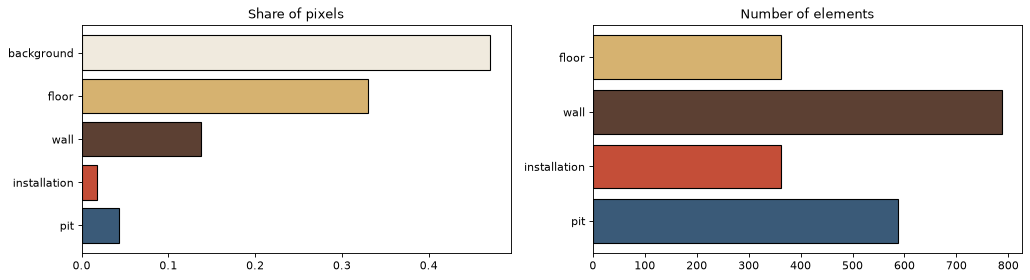

In [4]:
c = E["coverage"]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].barh(CLASSES, [c["pixel_share"][k] for k in CLASSES], color=PALETTE / 255, edgecolor="k"); ax[0].set_title("Share of pixels"); ax[0].invert_yaxis()
ax[1].barh(CLASSES[1:], [c["elements_per_class"][k] for k in CLASSES[1:]], color=PALETTE[1:] / 255, edgecolor="k"); ax[1].set_title("Number of elements"); ax[1].invert_yaxis()
plt.tight_layout(); plt.show()
print("layouts that contain each class:", c["layouts_with_class"])
print("compositions:", c["composition_tags"])
print("periods:", c["periods"])

**Decision.** Installations are under 2% of the pixels although they appear in two thirds of the layouts. The loss uses class weights of 1/sqrt(frequency) and a Dice term, and results are reported per class.

## 4. Label quality

The diffusion model does not draw the mask exactly, so the label is noisy. Two independent signals: agreement with an external segmenter, and agreement with a U-Net trained on the other half of the layouts.

{
 "segformer_agreement": {
  "median": 0.241,
  "share>=0.3": 0.3383,
  "share>=0.5": 0.0533,
  "share>=0.8": 0.0083
 },
 "HAR_median": 0.482,
 "crossfit_oof_miou": {
  "median": 0.677,
  "n": 540
 }
}


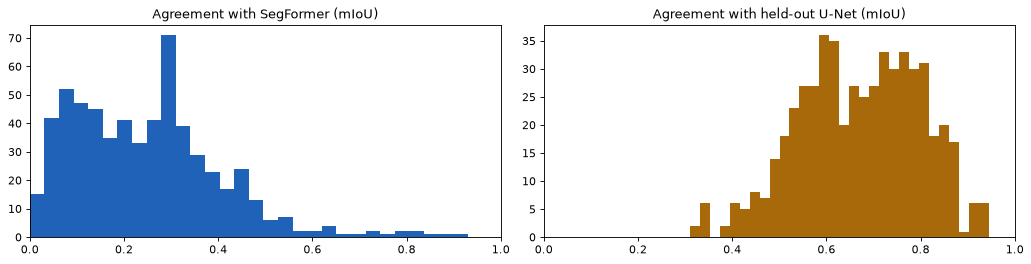

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
ax[0].hist(raw["agree"], bins=30, color="#1F62B8"); ax[0].set_title("Agreement with SegFormer (mIoU)"); ax[0].set_xlim(0, 1)
ax[1].hist(raw["oof"], bins=30, color="#A8690A"); ax[1].set_title("Agreement with held-out U-Net (mIoU)"); ax[1].set_xlim(0, 1)
plt.tight_layout(); plt.show()
print(json.dumps(E["label_quality"], indent=1))

**Decision.** The two signals barely agree with each other, so no image is dropped by either of them alone. A 3-pixel band around class borders is ignored in training, and a 40-image sample waits for human rating (issue 3).

## 5. Variability: what decides how an image looks?

{
 "pixel_correlation_64px": {
  "same_layout_diff_seed": {
   "median": 0.245,
   "n_pairs": 300
  },
  "diff_layout_same_seed": {
   "median": 0.381,
   "n_pairs": 89700
  },
  "diff_layout_diff_seed": {
   "median": 0.119,
   "n_pairs": 89700
  }
 },
 "n_diffusion_seeds": 2,
 "unique_prompts": 56
}


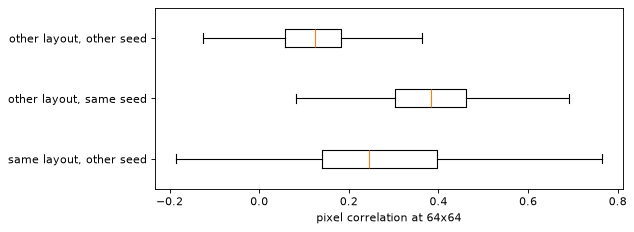

In [6]:
lab = ["same layout, other seed", "other layout, same seed", "other layout, other seed"]
keys = ["same_layout_diff_seed", "diff_layout_same_seed", "diff_layout_diff_seed"]
fig, ax = plt.subplots(figsize=(8, 3))
ax.boxplot([raw["corr"][k] for k in keys], orientation="horizontal", showfliers=False)
ax.set_yticks([1, 2, 3]); ax.set_yticklabels(lab); ax.set_xlabel("pixel correlation at 64x64")
plt.tight_layout(); plt.show()
print(json.dumps(E["variability"], indent=1))

**Decision.** Two different layouts with the same diffusion seed look more alike than one layout with two seeds. Only two seeds were used for all 300 layouts, so the set has less variety than its size suggests. Version 2 uses a unique seed per image.

## 6. Realism: generated against real

Only the 14 development tiles are used, so that no decision depends on the test tiles.

{
 "n_synth": 200,
 "n_real": 14,
 "stats": {
  "brightness": {
   "synth_median": 0.4323,
   "real_median": 0.4809,
   "ks": 0.488
  },
  "contrast": {
   "synth_median": 0.2027,
   "real_median": 0.1714,
   "ks": 0.454
  },
  "saturation": {
   "synth_median": 0.467,
   "real_median": 0.1304,
   "ks": 1.0
  },
  "sharpness": {
   "synth_median": 0.0762,
   "real_median": 0.044,
   "ks": 0.735
  },
  "green_frac": {
   "synth_median": 0.0,
   "real_median": 0.0242,
   "ks": 0.585
  }
 },
 "wall_thickness_share_of_side": {
  "synth_median": 0.0977,
  "real_median": 0.0418
 },
 "wall_pixel_share": {
  "synth_median": 0.1416,
  "real_median": 0.1049
 }
}


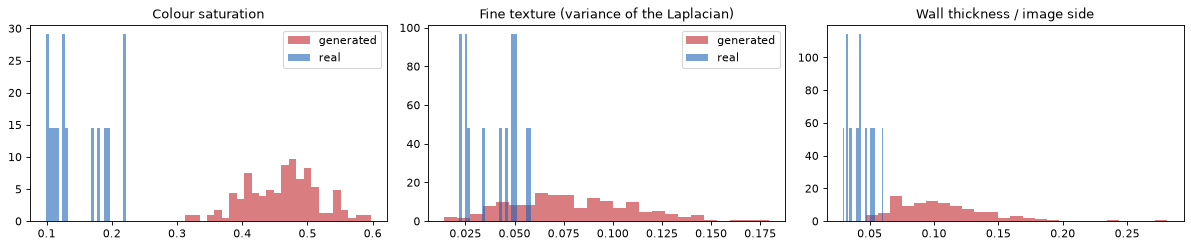

In [7]:
R = E["realism"]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.2))
for a, k, t in zip(ax, ["saturation", "sharpness"], ["Colour saturation", "Fine texture (variance of the Laplacian)"]):
    a.hist([d[k] for d in raw["synth"]], bins=25, density=True, alpha=.6, color="#C1272D", label="generated")
    a.hist([d[k] for d in raw["real"]], bins=25, density=True, alpha=.6, color="#1F62B8", label="real"); a.set_title(t); a.legend()
ax[2].hist(raw["thick_synth"], bins=25, density=True, alpha=.6, color="#C1272D"); ax[2].hist(raw["thick_real"], bins=25, density=True, alpha=.6, color="#1F62B8"); ax[2].set_title("Wall thickness / image side")
plt.tight_layout(); plt.show()
print(json.dumps(R, indent=1))

**Decision.** Generated images are about 3.6 times more saturated, have more fine texture, and draw walls about twice as thick relative to the frame. Input size is chosen on the development tiles, and version 2 changes prompts, colour and scale. Fourteen tiles from eight areas are a small sample.

## 7. Leakage

In [8]:
print(json.dumps(E["leakage"], indent=1))
ov = load("04_cv_experiment/annotation/real_walls_overlaps.json")
rows = list(csv.DictReader(open(ROOT / "04_cv_experiment/annotation/real_walls_manifest.csv", encoding="utf-8")))
used = {r["tile"] for r in rows if r["split"] != "duplicate"}
pairs = [o for o in ov["overlaps"] if o["a"] in used and o["b"] in used]
print(len(ov["overlaps"]), "overlapping pairs among all", len(rows), "tiles,", len(pairs), "among the", len(used), "tiles that are used")
print("identical tiles annotated twice:", ov["annotation_agreement_on_identical_tiles"])
for sp in ("dev", "test", "duplicate"):
    r = [x for x in rows if x["split"] == sp]
    print(sp, len(r), "tiles in", len({x["group"] for x in r}), "overlap groups, mean wall share", round(float(np.mean([float(x["wall_frac"]) for x in r])), 3))

{
 "split_images": {
  "train": 480,
  "val": 60,
  "test": 60
 },
 "split_layouts": {
  "train": 240,
  "val": 30,
  "test": 30
 },
 "layouts_shared_between_splits": 0,
 "identical_masks_across_layouts": 0,
 "near_duplicate_pairs_dhash<=6": 12,
 "near_duplicate_pairs_across_splits": 5
}
36 overlapping pairs among all 56 tiles, 30 among the 54 tiles that are used
identical tiles annotated twice: [{'a': 'tile_1_12', 'b': 'tile_77_12', 'iou': 0.7258}, {'a': 'tile_2_80', 'b': 'tile_77_1', 'iou': 0.6882}]
dev 14 tiles in 8 overlap groups, mean wall share 0.098
test 40 tiles in 22 overlap groups, mean wall share 0.114
duplicate 2 tiles in 2 overlap groups, mean wall share 0.119


**Decision.** Generated images are split by layout, never by image. Twelve image pairs look alike by perceptual hash, five of them across splits; their label masks differ (they are different layouts with a similar composition and the same seed), so they are kept. The real tiles overlap with their neighbours by a quarter or at a corner, and two tiles are second copies of the same photo, so they are split by overlap group. A random split would have leaked. The two photos labelled twice give a first look at label consistency: IoU of about 0.7.

## 8. Difficulty

The comparison of weak and strong models is in `02_baselines_and_errors.ipynb`.